# 01 — Exploração Inicial dos Dados
**Olist Analytics Hub | Etapa 1 de 7**

**Objetivo:** Entender o schema relacional, inspecionar a qualidade dos dados e formular as perguntas de negócio que guiarão toda a análise.

---
### Perguntas que este notebook responde
1. Quantos registros e colunas tem cada dataset?
2. Como as tabelas se relacionam entre si?
3. Qual a qualidade dos dados (nulos, duplicatas, tipos)?
4. Quais são as distribuições básicas das variáveis-chave?

In [1]:
import sys
sys.path.insert(0, '..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from IPython.display import display, HTML

from src.data_loader import load_all_raw, validate_datasets, get_dataset_info
from src.visualizations import setup_style, save_fig

setup_style()
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

print('✓ Ambiente configurado.')

✓ Ambiente configurado.


## 1. Carregamento dos Dados

In [2]:
print('Carregando datasets...')
datasets = load_all_raw()

Carregando datasets...


  ✓ orders                               99,441 linhas × 8 colunas
  ✓ order_items                         112,650 linhas × 7 colunas


  ✓ order_payments                      103,886 linhas × 5 colunas


  ✓ order_reviews                        99,224 linhas × 7 colunas
  ✓ customers                            99,441 linhas × 5 colunas
  ✓ products                             32,951 linhas × 9 colunas
  ✓ sellers                               3,095 linhas × 4 colunas


  ✓ geolocation                         1,000,163 linhas × 5 colunas
  ✓ product_category_translation             71 linhas × 2 colunas


In [3]:
# Visão geral de todos os datasets
info = get_dataset_info(datasets)
display(info.style.background_gradient(subset=['linhas'], cmap='Blues'))

,linhas,colunas,nulos_total,pct_nulos,memoria_mb
dataset,,,,,
orders,99441,8,4908,0.62%,52.94
order_items,112650,7,0,0.00%,35.99
order_payments,103886,5,0,0.00%,16.23
order_reviews,99224,7,145903,21.01%,39.12
customers,99441,5,0,0.00%,26.59
products,32951,9,2448,0.83%,6.30
sellers,3095,4,0,0.00%,0.59
geolocation,1000163,5,0,0.00%,129.38
product_category_translation,71,2,0,0.00%,0.01


## 2. Validação das Chaves Primárias

In [4]:
print('Validando integridade dos datasets...')
validate_datasets(datasets)

Validando integridade dos datasets...
  ✓ orders.order_id: sem duplicatas
  ✓ customers.customer_id: sem duplicatas
  ✓ products.product_id: sem duplicatas
  ✓ sellers.seller_id: sem duplicatas


True

## 3. Schema Relacional

```
┌─────────────────────┐       ┌──────────────────────┐
│     customers       │       │       sellers        │
│ PK: customer_id     │       │ PK: seller_id        │
└──────────┬──────────┘       └──────────┬───────────┘
           │                             │
           ▼                             ▼
┌─────────────────────────────────────────────────────┐
│                       orders                        │
│ PK: order_id  │  FK: customer_id                    │
└────────────────────────┬────────────────────────────┘
                         │
          ┌──────────────┼──────────────┬─────────────┐
          ▼              ▼              ▼             ▼
   ┌─────────────┐ ┌──────────┐ ┌──────────┐ ┌──────────────┐
   │ order_items │ │ payments │ │  reviews │ │  geolocation │
   │ FK:order_id │ │FK:ord_id │ │FK:ord_id │ │  (zip_code)  │
   │ FK:product_id│ └──────────┘ └──────────┘ └──────────────┘
   │ FK:seller_id│
   └──────┬──────┘
          ▼
   ┌─────────────┐
   │  products   │
   │PK:product_id│
   └─────────────┘
```

## 4. Inspeção Detalhada por Tabela

In [5]:
# ── Orders ────────────────────────────────────────────────────────────────────
orders = datasets['orders']
print('=== ORDERS ===')
print(f'Shape: {orders.shape}')
print('\nTipos:')
print(orders.dtypes.to_string())
print('\nPrimeiras linhas:')
display(orders.head(3))

=== ORDERS ===
Shape: (99441, 8)

Tipos:
order_id                         object
customer_id                      object
order_status                     object
order_purchase_timestamp         object
order_approved_at                object
order_delivered_carrier_date     object
order_delivered_customer_date    object
order_estimated_delivery_date    object

Primeiras linhas:


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00


In [6]:
# Distribuição do status dos pedidos
status_counts = orders['order_status'].value_counts()
print('Distribuição de Status:')
print(status_counts)
print(f'\nPedidos entregues: {status_counts.get("delivered", 0) / len(orders):.1%}')

Distribuição de Status:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Pedidos entregues: 97.0%


In [7]:
# Nulos por coluna em orders
null_analysis = orders.isnull().sum().rename('nulos')
null_analysis = null_analysis[null_analysis > 0].sort_values(ascending=False)
null_pct = (null_analysis / len(orders) * 100).rename('%')
display(pd.concat([null_analysis, null_pct], axis=1))

,nulos,%
order_delivered_customer_date,2965,2.98
order_delivered_carrier_date,1783,1.79
order_approved_at,160,0.16


In [8]:
# ── Order Items ───────────────────────────────────────────────────────────────
items = datasets['order_items']
print('=== ORDER ITEMS ===')
print(f'Shape: {items.shape}')
display(items.head(3))
print('\nEstatísticas de preço:')
display(items[['price', 'freight_value']].describe())

=== ORDER ITEMS ===
Shape: (112650, 7)


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87



Estatísticas de preço:


,price,freight_value
count,"112,650.00","112,650.00"
mean,120.65,19.99
std,183.63,15.81
min,0.85,0.00
25%,39.90,13.08
50%,74.99,16.26
75%,134.90,21.15
max,"6,735.00",409.68


In [9]:
# ── Customers ─────────────────────────────────────────────────────────────────
customers = datasets['customers']
print('=== CUSTOMERS ===')
print(f'Shape: {customers.shape}')
print(f'Clientes únicos: {customers["customer_unique_id"].nunique():,}')
print(f'Estados: {customers["customer_state"].nunique()}')
print('\nTop 10 estados por volume de clientes:')
print(customers['customer_state'].value_counts().head(10).to_string())

=== CUSTOMERS ===
Shape: (99441, 5)
Clientes únicos: 96,096
Estados: 27

Top 10 estados por volume de clientes:
customer_state
SP    41746
RJ    12852
MG    11635
RS     5466
PR     5045
SC     3637
BA     3380
DF     2140
ES     2033
GO     2020


In [10]:
# ── Products ──────────────────────────────────────────────────────────────────
products = datasets['products']
translation = datasets['product_category_translation']
print('=== PRODUCTS ===')
print(f'Shape: {products.shape}')
print(f'Categorias: {products["product_category_name"].nunique()}')
print('\nNulos por coluna:')
print(products.isnull().sum()[products.isnull().sum() > 0].to_string())

=== PRODUCTS ===
Shape: (32951, 9)
Categorias: 73

Nulos por coluna:
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2


In [11]:
# ── Reviews ───────────────────────────────────────────────────────────────────
reviews = datasets['order_reviews']
print('=== ORDER REVIEWS ===')
print(f'Shape: {reviews.shape}')
print(f'Pedidos com review: {reviews["order_id"].nunique():,}')
print('\nDistribuição de notas:')
print(reviews['review_score'].value_counts().sort_index().to_string())
print(f'\nNota média: {reviews["review_score"].mean():.2f}')

=== ORDER REVIEWS ===
Shape: (99224, 7)
Pedidos com review: 98,673

Distribuição de notas:
review_score
1    11424
2     3151
3     8179
4    19142
5    57328

Nota média: 4.09


## 5. Visualizações Iniciais

  ✓ Figura salva: 01_visao_geral.png


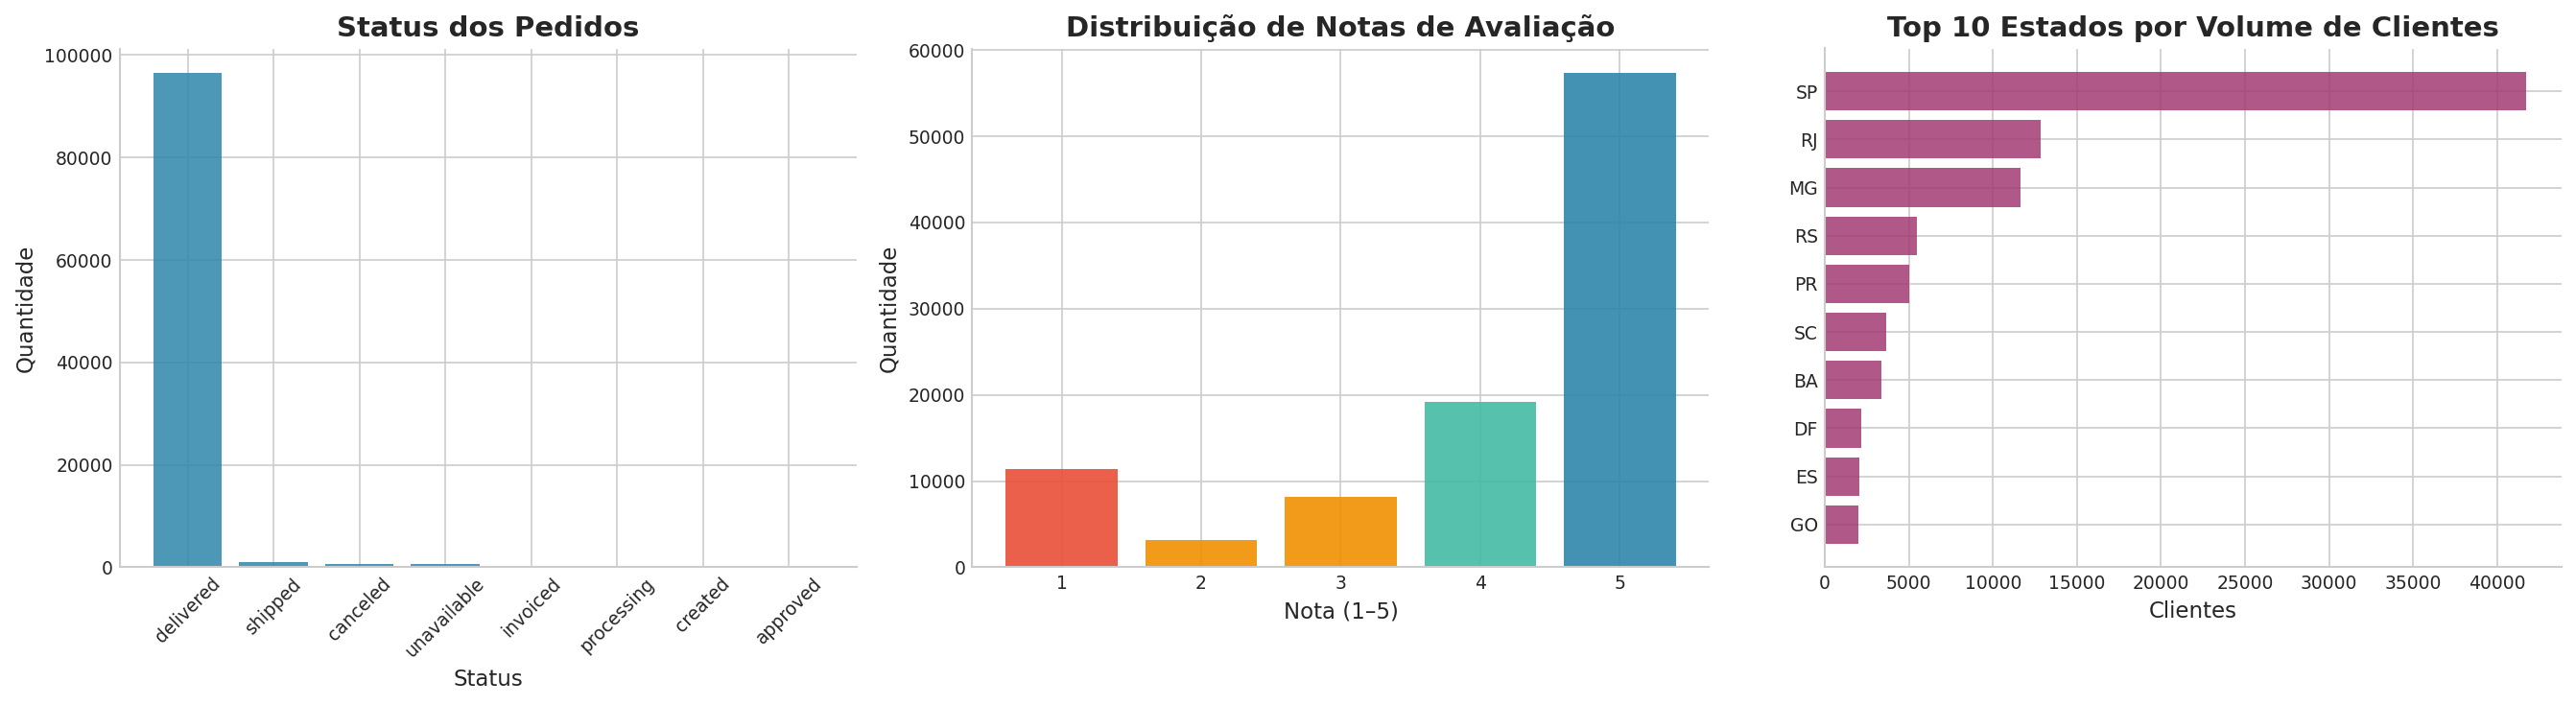

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Status dos pedidos
status_data = orders['order_status'].value_counts()
axes[0].bar(status_data.index, status_data.values, color='#2E86AB', alpha=0.85)
axes[0].set_title('Status dos Pedidos', fontweight='bold')
axes[0].set_xlabel('Status')
axes[0].set_ylabel('Quantidade')
axes[0].tick_params(axis='x', rotation=45)

# 2. Distribuição de notas de avaliação
review_data = reviews['review_score'].value_counts().sort_index()
colors_review = ['#E94F37', '#F18F01', '#F18F01', '#44BBA4', '#2E86AB']
axes[1].bar(review_data.index, review_data.values, color=colors_review, alpha=0.9)
axes[1].set_title('Distribuição de Notas de Avaliação', fontweight='bold')
axes[1].set_xlabel('Nota (1–5)')
axes[1].set_ylabel('Quantidade')

# 3. Top 10 estados por clientes
state_data = customers['customer_state'].value_counts().head(10)
axes[2].barh(state_data.index, state_data.values, color='#A23B72', alpha=0.85)
axes[2].set_title('Top 10 Estados por Volume de Clientes', fontweight='bold')
axes[2].set_xlabel('Clientes')
axes[2].invert_yaxis()

plt.tight_layout()
save_fig('01_visao_geral')
plt.show()

  ✓ Figura salva: 01_distribuicao_precos.png


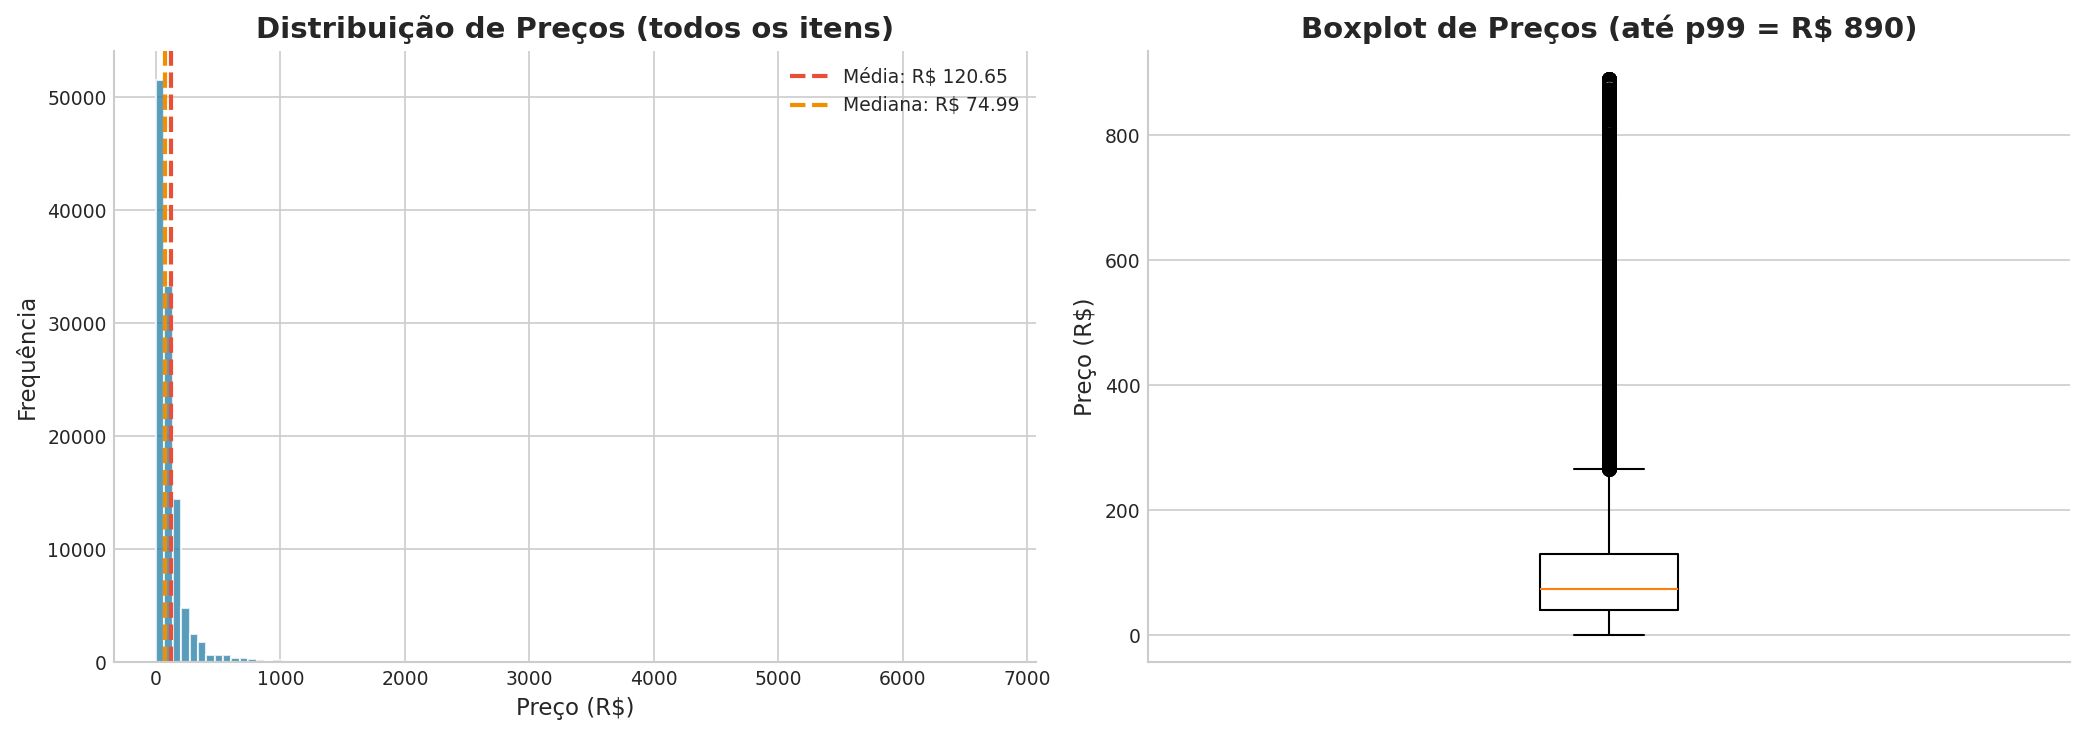

In [13]:
# Distribuição de preços com outliers
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(items['price'], bins=100, color='#2E86AB', alpha=0.8, edgecolor='white')
axes[0].set_title('Distribuição de Preços (todos os itens)', fontweight='bold')
axes[0].set_xlabel('Preço (R$)')
axes[0].set_ylabel('Frequência')
axes[0].axvline(items['price'].mean(), color='#E94F37', linestyle='--', linewidth=2, label=f'Média: R$ {items["price"].mean():.2f}')
axes[0].axvline(items['price'].median(), color='#F18F01', linestyle='--', linewidth=2, label=f'Mediana: R$ {items["price"].median():.2f}')
axes[0].legend()

# Boxplot sem outliers extremos (percentil 99)
p99 = items['price'].quantile(0.99)
axes[1].boxplot(items.loc[items['price'] <= p99, 'price'], vert=True)
axes[1].set_title(f'Boxplot de Preços (até p99 = R$ {p99:.0f})', fontweight='bold')
axes[1].set_ylabel('Preço (R$)')
axes[1].set_xticks([])

plt.tight_layout()
save_fig('01_distribuicao_precos')
plt.show()

## 6. Mapa de Nulos (Heat Map)

Visualização da completude de cada dataset para identificar quais tabelas precisarão de mais tratamento.

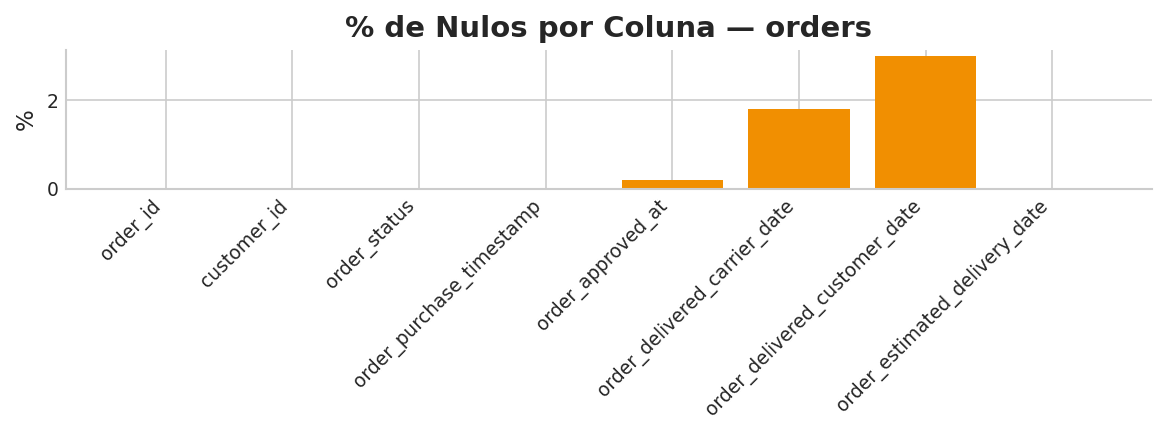

  order_items: sem nulos.
  order_payments: sem nulos.


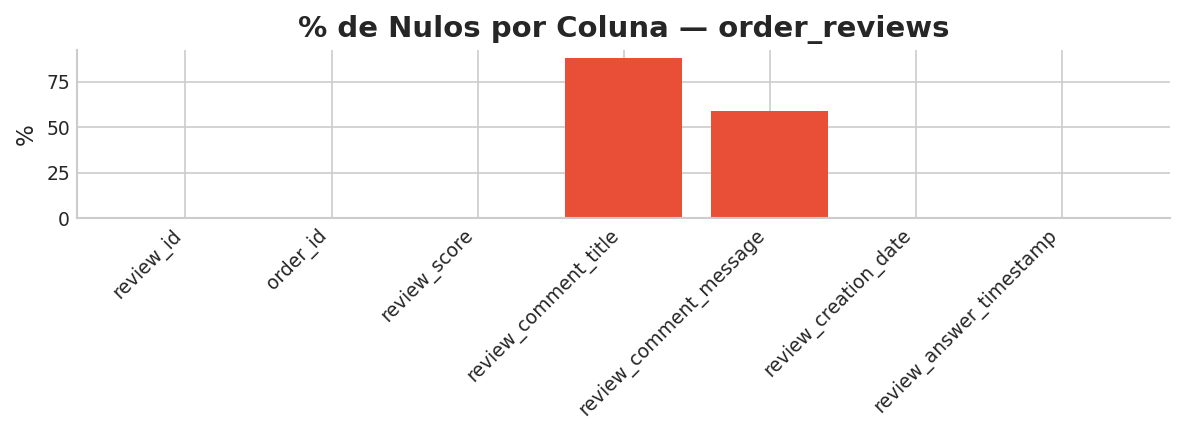

  customers: sem nulos.


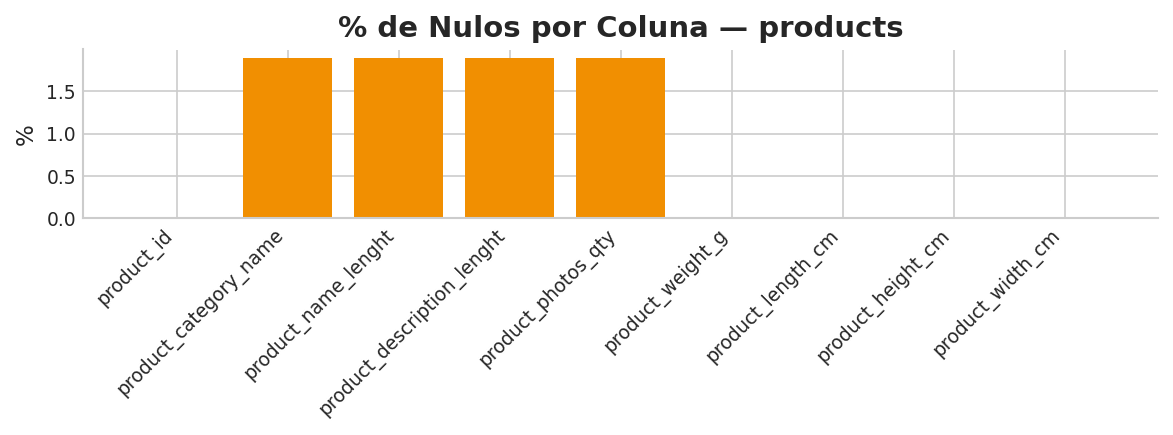

  sellers: sem nulos.
  geolocation: sem nulos.
  product_category_translation: sem nulos.


In [14]:
def null_heatmap(df, title):
    null_pct = (df.isnull().mean() * 100).round(1)
    if null_pct.sum() == 0:
        print(f'  {title}: sem nulos.')
        return
    fig, ax = plt.subplots(figsize=(max(8, len(df.columns) * 0.6), 3))
    ax.bar(null_pct.index, null_pct.values, color=['#E94F37' if v > 5 else '#F18F01' if v > 0 else '#44BBA4' for v in null_pct.values])
    ax.set_title(f'% de Nulos por Coluna — {title}', fontweight='bold')
    ax.set_ylabel('%')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

for name, df in datasets.items():
    null_heatmap(df, name)

## 7. Sumário e Conclusões

| Aspecto | Achado |
|---------|--------|
| Volume total | ~100k pedidos, 9 tabelas |
| Pedidos entregues | ~97% do total |
| Clientes únicos | 96.096 (baixa recompra) |
| Nota média | 4,09/5 |
| Principal estado | SP (42,0% dos clientes) |
| Nulos críticos | Datas de entrega ausentes em pedidos cancelados/em trânsito |

### Decisões de limpeza para o próximo notebook:
1. Converter todas as colunas de data para `datetime`
2. Filtrar pedidos com status `delivered` para análises de entrega
3. Preencher nulos de peso/dimensão de produtos com mediana por categoria
4. Agregar pagamentos múltiplos por pedido (parcelamento)
5. Manter apenas 1 review por pedido (o mais recente)

---
**Próximo:** `02_limpeza_e_enriquecimento.ipynb`